# Proyecto Churn: EDA

## Entendimiento Contextual

## Metadata

In [1]:
#--- Metadatos del proyecto
from datetime import datetime
AUTOR = "Mgtr. Ronald Osorio"
FECHA_MODIFICACION = datetime.now().strftime("%d/%m/%Y %H:%M:%S")

print(f"Autor: {AUTOR}")
print(f"Última modificación: {FECHA_MODIFICACION}\n" + "-"*40)

Autor: Mgtr. Ronald Osorio
Última modificación: 22/10/2026 11:30:48
----------------------------------------


## Entorno

In [2]:
# General
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Módulos locales
import sys
sys.path.append('C:/Users/games/OneDrive/DS/Clases/Utils')
from eda_classification import *
from descriptive_analysis import *

## Dataset

In [3]:
import os

ruta=os.getcwd()
ruta_csv = os.path.join(ruta, 'churn_limpios.csv')
df = pd.read_csv(ruta_csv)

## Renombrado de Columnas

No es necesario

## Distribución de Columnas

In [4]:
target = 'exited'
df_num = df[['credit_score', 'age', 'balance', 'estimated_salary', 'point_earned', 'exited']]
df_bina = df[['gender', 'has_cr_card', 'is_active_member', 'complain', 'exited' ]]
df_tiem = df[[]]
df_cat = df[[ 'geography', 'card_type', 'tenure','num_of_products', 'satisfaction_score', 'exited']]


# Configuración. Columnas para transformar
columnas_cat = ['geography', 'card_type', 'tenure', 'num_of_products', 'satisfaction_score']

# Transformando
df[columnas_cat] = df[columnas_cat].astype('category')
df_cat[columnas_cat] = df_cat[columnas_cat].astype('category')

## Hallazgos Clave
| Objetivos | Descripción | Columnas | Listo |
| :--- | :--- | :--- | :--- |
| 1. Datos faltantes y patrones |Ninguno | |✓ |
| 2. Duplicados |Ninguno | |✓ |
| 3. Valores atípicos | credit_score, age	| |✓ |
| 4. Desbalance de clases / Codificación | * No, 20.4% <br> * Métricas recomendadas: Acc, F-1|  |✓ |
| 5. Poder predictivo de las variables |Baja importancia | * credit_score,<br> * point_earned,<br> * has_cr_card,<br> * estimated_salary<br> |✓ |
| 6. Escalado de datos| Sí | |✓ |
| 7. Asimetría (Skew)| Sí | |✓ |
| 8. Unimodal| Sí | |✓ |
| 9. Relaciones no lineales y asociaciones |Baja importancia | * card_type,<br> * tenure,<br> * satisfaction_score |✓ |
| 10. Multicolinealidad |Ninguna | |✓ |
| 11. Crear nuevas características| No | |✓ |
| 12. Alta dimensionalidad |* No, 3 variables influyen en el objetivo<br> * complain es un candidato crítico de Data Leakage  | |✓ |
| 13. Normalizador |Ninguno | |✓ |
| 14. Otros |Ninguno | |✓ |

Prioridades clave para clasificación
| Factor | Modelos lineales / Redes neuronales / KNN | Modelos basados en árboles (Random Forest, XGBoost) |
| :--- | :--- | :--- |
| **Desbalance de clases (Proporciones)** | 🚨 **Crítico** (Sesga el límite de decisión) | 🚨 **Crítico** (El algoritmo ignora la clase minoritaria para maximizar la exactitud) |
| **Solapamiento (Separación)** | 🚨 **Crítico** (Difícil encontrar un hiperplano de separación limpio) | ⚠️ **Moderado** (Lo maneja creciendo más profundo, pero con riesgo de sobreajuste) |
| **One-Hot Encoding** | 🚨 **Crítico** (Necesario para que las variables categóricas funcionen) | ❌ **No recomendado** (Crea alta dispersión y diluye la importancia de las características) |
| **Codificación Ordinal / Target** | ❌ **No recomendado** (Introduce una jerarquía/orden numérico falso) | 🚨 **Crítico** (Muy eficiente y mantiene las estructuras de árbol simples) |
| **Bi / multi Modal** | 🚨 Importante (Puede causar problemas de separación no lineal) | ❌ **Irrelevante** (No se requiere acción) |

## Análisis Descriptivo

### Estructura

#### Muestra

In [5]:
df.head(3)

,customer_id,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited,complain,satisfaction_score,card_type,point_earned
0,15576156,710,Spain,0,28,6,0.00,1,1,0,48426.98,0,0,3,GOLD,406
1,15708791,584,Spain,1,32,9,85534.83,1,0,0,169137.24,0,0,5,PLATINUM,226
2,15737792,818,France,0,31,1,186796.37,1,0,0,178252.63,0,0,4,PLATINUM,417


In [6]:
df.tail(3)

,customer_id,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited,complain,satisfaction_score,card_type,point_earned
9997,15722010,621,Spain,1,53,9,170491.84,1,1,0,35588.07,1,1,3,PLATINUM,777
9998,15706810,606,Germany,0,32,1,106301.85,2,0,1,59061.25,0,0,3,GOLD,469
9999,15689952,724,Spain,1,41,5,0.00,1,0,1,115753.94,0,0,5,DIAMOND,540


#### Metadata

In [7]:
basic_info(df)


RESUMEN GENERAL DE DATOS
Dimensiones → Filas: 10,000 | Columnas: 16
                       dtype  mem_default_bytes  mem_deep_bytes  unique  %_unique  zeros  negatives         min         max      range
customer_id            int64              80000           80000   10000    100.00      0          0  15565701.0  15815690.0   249989.0
credit_score           int64              80000           80000     460      4.60      0          0       350.0       850.0      500.0
geography           category              10024           10165       3      0.03      0          0        None        None       None
gender                 int64              80000           80000       2      0.02   4543          0         0.0         1.0        1.0
age                    int64              80000           80000      70      0.70      0          0        18.0        92.0       74.0
tenure              category              10088           10088      11      0.11      0          0        None        No

#### Estadísticas Descriptivas

In [8]:
description(df)


ESTADÍSTICAS DESCRIPTIVAS


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,CV,outliers,outliers_%
customer_id,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00,0.001149,-1.196113,0.004585,0,0.00
credit_score,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00,-0.071607,-0.425726,0.148577,15,0.15
gender,10000.0,5.457000e-01,0.497932,0.00,0.00,1.000000e+00,1.000000e+00,1.00,-0.183596,-1.966686,0.912465,0,0.00
age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00,1.011320,1.395347,0.269458,359,3.59
balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09,-0.141109,-1.489412,0.815803,0,0.00
has_cr_card,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00,-0.901812,-1.186973,0.646124,0,0.00
is_active_member,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00,-0.060437,-1.996747,0.970291,0,0.00
estimated_salary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48,0.002085,-1.181518,0.574586,0,0.00
exited,10000.0,2.038000e-01,0.402842,0.00,0.00,0.000000e+00,0.000000e+00,1.00,1.470845,0.163419,1.976654,2038,20.38
complain,10000.0,2.044000e-01,0.403283,0.00,0.00,0.000000e+00,0.000000e+00,1.00,1.466263,0.149956,1.973007,2044,20.44



### VERIFICACIONES (CHECKS) ###

    ASIMETRÍA / SKEWNESS (|skew|):
    • < 1              : Aproximadamente simétrica → OK
    • 1–2              : Moderadamente sesgada → considerar transformación log/sqrt
    • > 2              : Altamente sesgada → transformación recomendada
    
    CURTOSIS:
    • ≈ 3              : Colas normales (mesocúrtica) → OK
    • < 3              : Colas ligeras (platicúrtica) → OK
    • > 3              : Colas pesadas (leptocúrtica) → verificar outliers
    
    COEFICIENTE DE VARIACIÓN (CV = std/mean):
    • < 0.5            : Baja variabilidad → variable estable
    • 0.5–1.0          : Variabilidad moderada → aceptable
    • > 1.0            : Alta variabilidad → considerar escalado/transformación
    
    OUTLIERS (%):
    • < 5%             : Bajo → OK
    • 5–10%            : Moderado → considerar tratamiento
    • > 10%            : Alto → investigar y potencialmente eliminar/acotar (cap)
    
    LÍMITES DE OUTLIERS:
    • lower_bound = Q1 - 1

## Limpieza de Datos

### Valores Nulos


PATRONES VISUALES DE DATOS FALTANTES


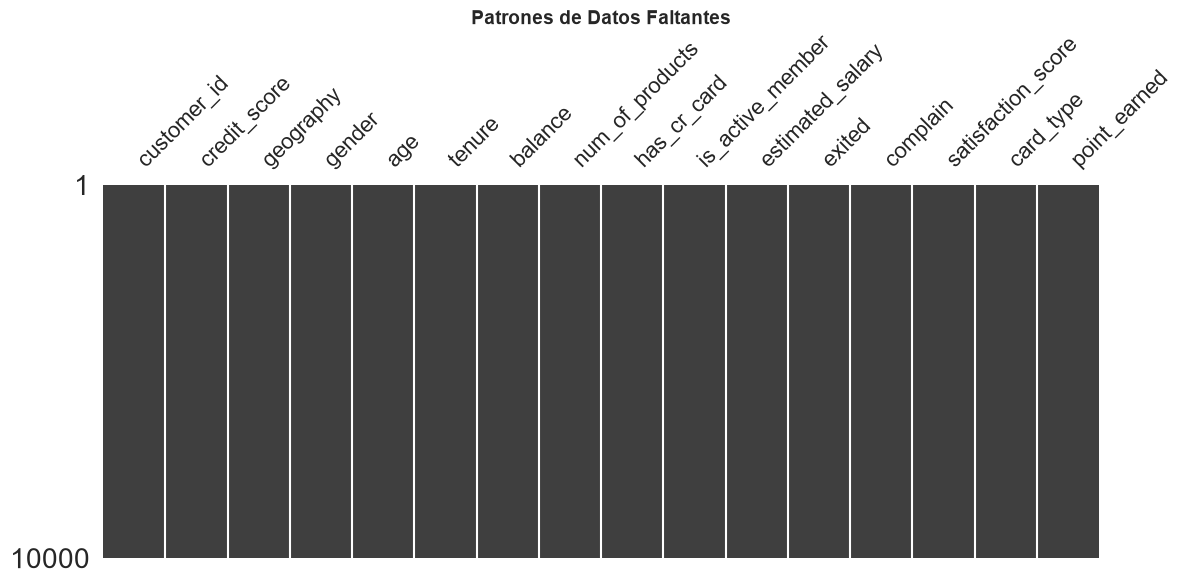


RESUMEN DE DATOS FALTANTES
                    null_count  %_missing  fake_nulls fake_values_found  total_missing  %_total
customer_id                  0        0.0           0                []              0      0.0
credit_score                 0        0.0           0                []              0      0.0
geography                    0        0.0           0                []              0      0.0
gender                       0        0.0           0                []              0      0.0
age                          0        0.0           0                []              0      0.0
tenure                       0        0.0           0                []              0      0.0
balance                      0        0.0           0                []              0      0.0
num_of_products              0        0.0           0                []              0      0.0
has_cr_card                  0        0.0           0                []              0      0.0
is_active_me

In [9]:
null_audit(df)

In [10]:
null_smart_dendrogram(df)

No se puede crear el dendrograma. Columnas con nulos: 0


In [11]:
null_smart_heatmap(df)

No se puede crear el mapa de calor. Columnas con nulos: 0


In [12]:
get_missing_raw_report(df, threshold=0.30)

No se encontraron filas que superen el umbral de valores faltantes.


### Duplicados

In [13]:
check_duplicates(df, subset = None)


ANÁLISIS DE DUPLICADOS
Filas con None duplicado: 0 (0.00%)
✓ No se encontraron duplicados


In [14]:
df = df.drop_duplicates(subset=None, keep='first')

### Valores Atípicos (Outliers)


Generando matriz de Outliers (Boxplots)...


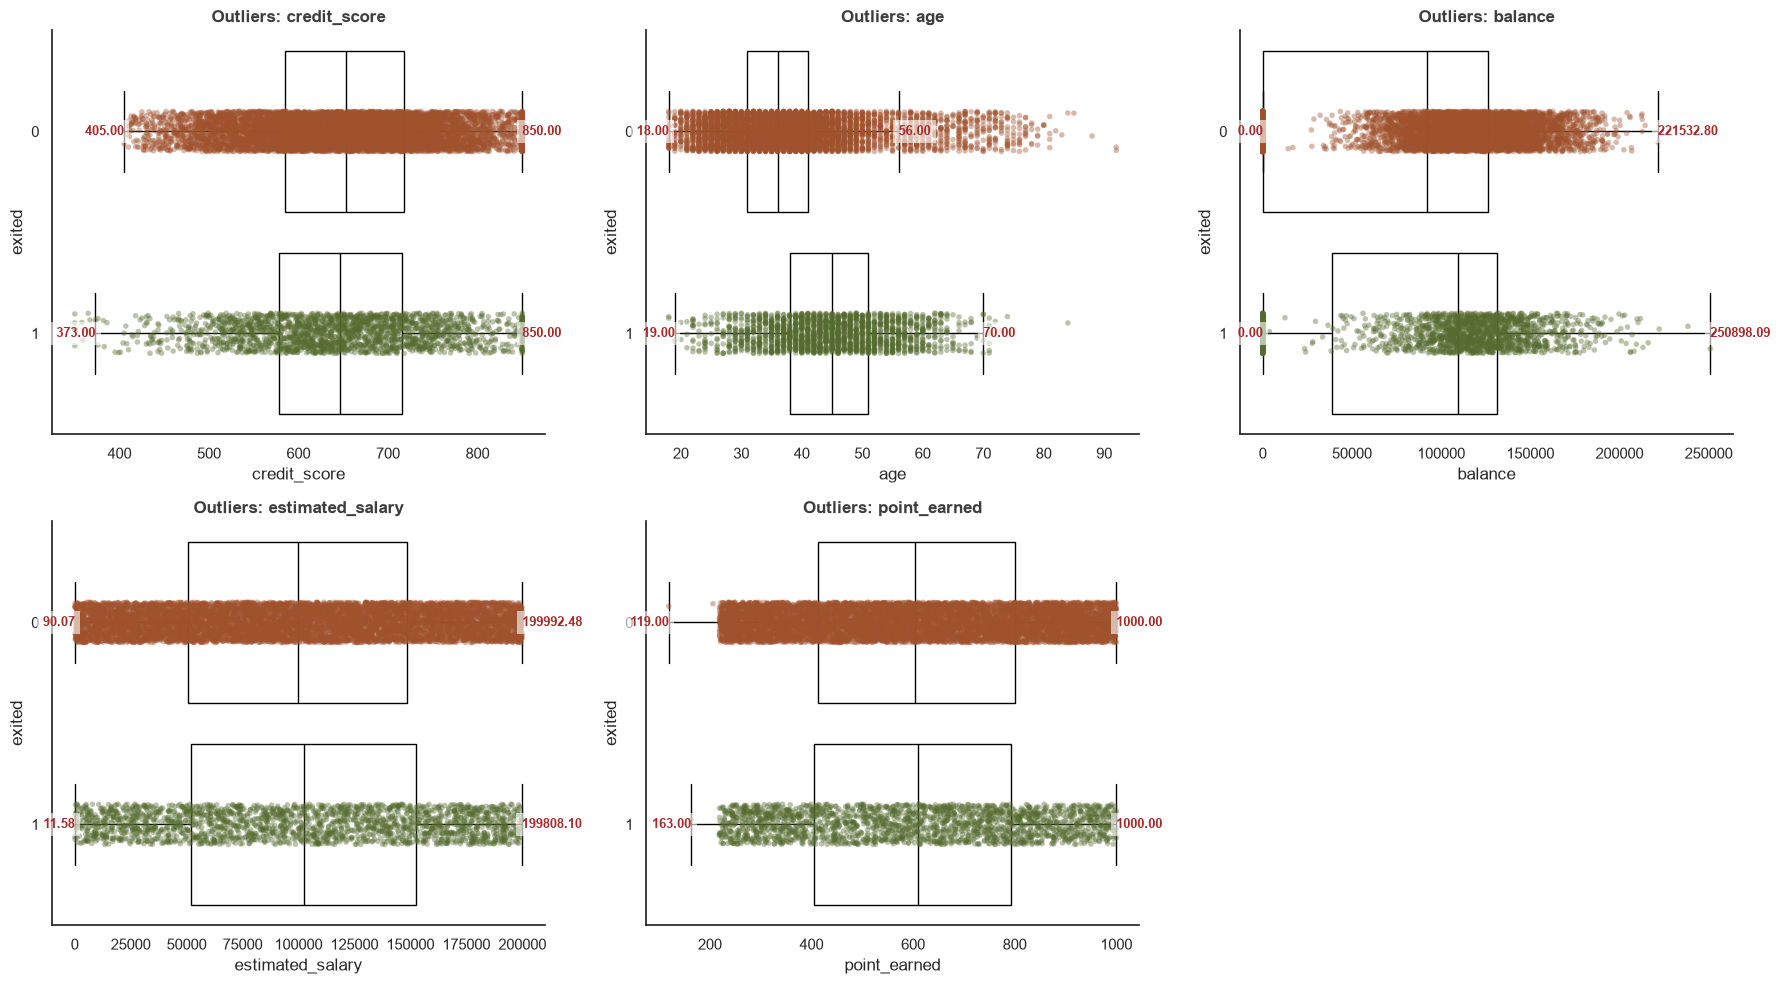

In [15]:
plot_outliers_cla(df_num, target)

## EDA (Análisis Exploratorio de Datos)

### Variable Objetivo

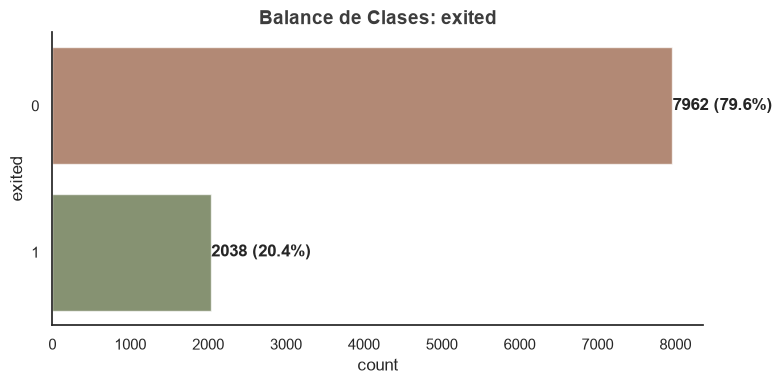


% Clase Minor. | Tamaño DF | Qué hacer    | Técnica                                   | Modelos Recomendados                               | Métricas
-------------------------------------------------------------------------------------------------------------------------------------------------------------------
<10%           | <1000     | Aumentar     | Sobremuestreo (duplicación o SMOTE simple)| Regresión Logística (class_weight), Random Forest  | Recall, F1-score, AUC-PR
<10%           | 1k–10k    | Aumentar     | SMOTE                                     | Random Forest, XGBoost, LightGBM                   | Recall, F1-score, AUC-PR
<10%           | >100k     | Mixto        | SMOTE + Submuestreo                       | XGBoost, LightGBM                                  | Recall, F1-score, AUC-PR
10–20%         | <1000     | Aumentar     | Sobremuestreo Simple                      | Regresión Logística (class_weight)                 | F1-score, Recall
10–20%         | 1k–10k    | 

In [16]:
plot_target_cla(df, "exited")

### Análisis Univariado

#### Evolución de la Serie Temporal del Objetivo:<br>
No data available

#### Distribuciones (Variables Numéricas)

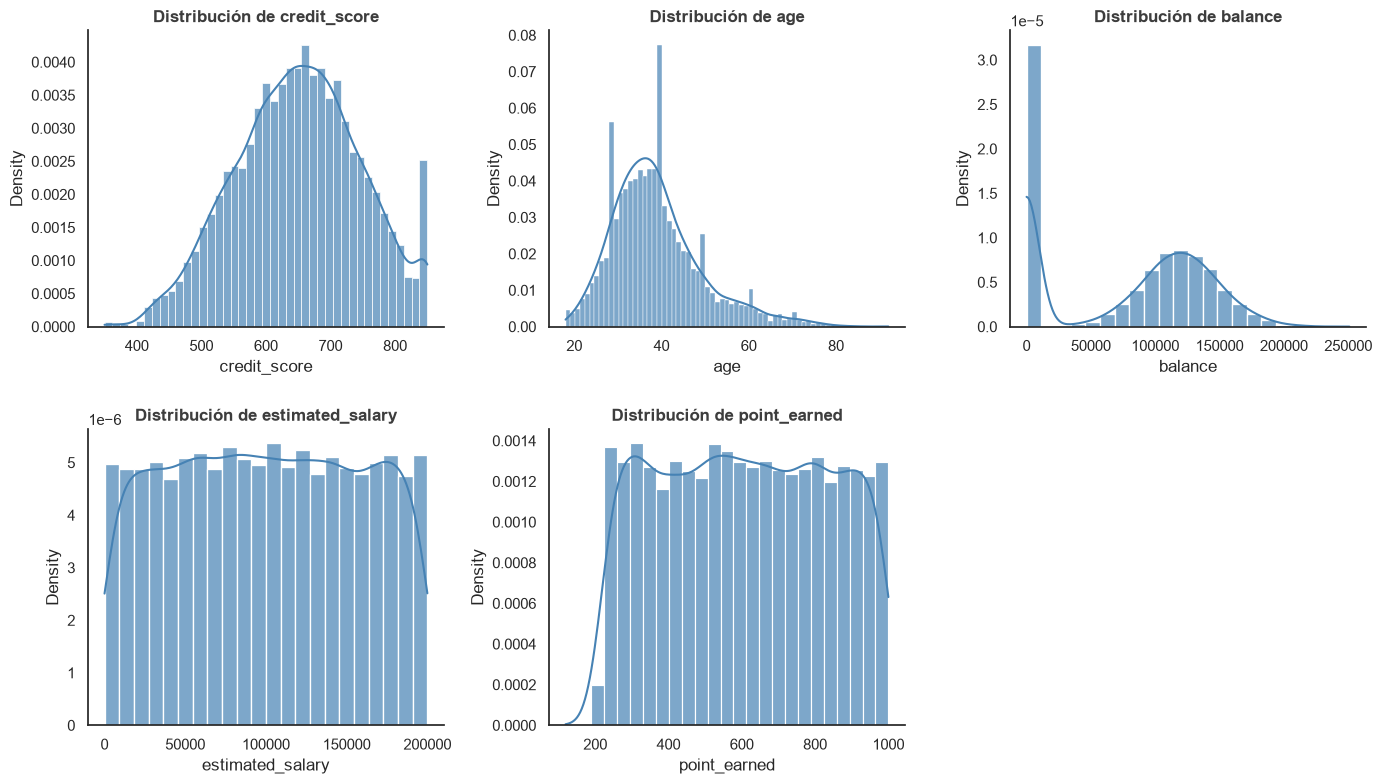

In [17]:
plot_all_numeric_distributions_cla_1(df_num, target)

#### Frecuencias de Variables Binarias

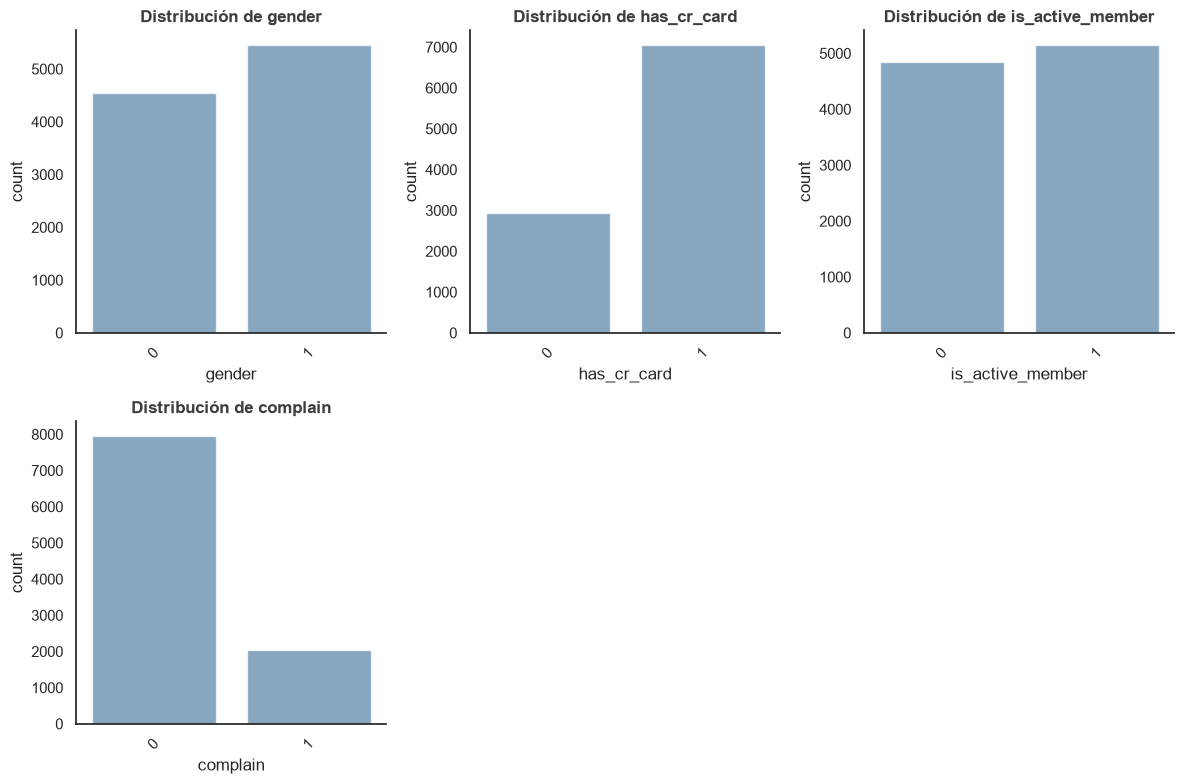

In [18]:
plot_categorical_counts_cla(df_bina, target, max_cat=10)

#### Frecuencias de Variables Categóricas

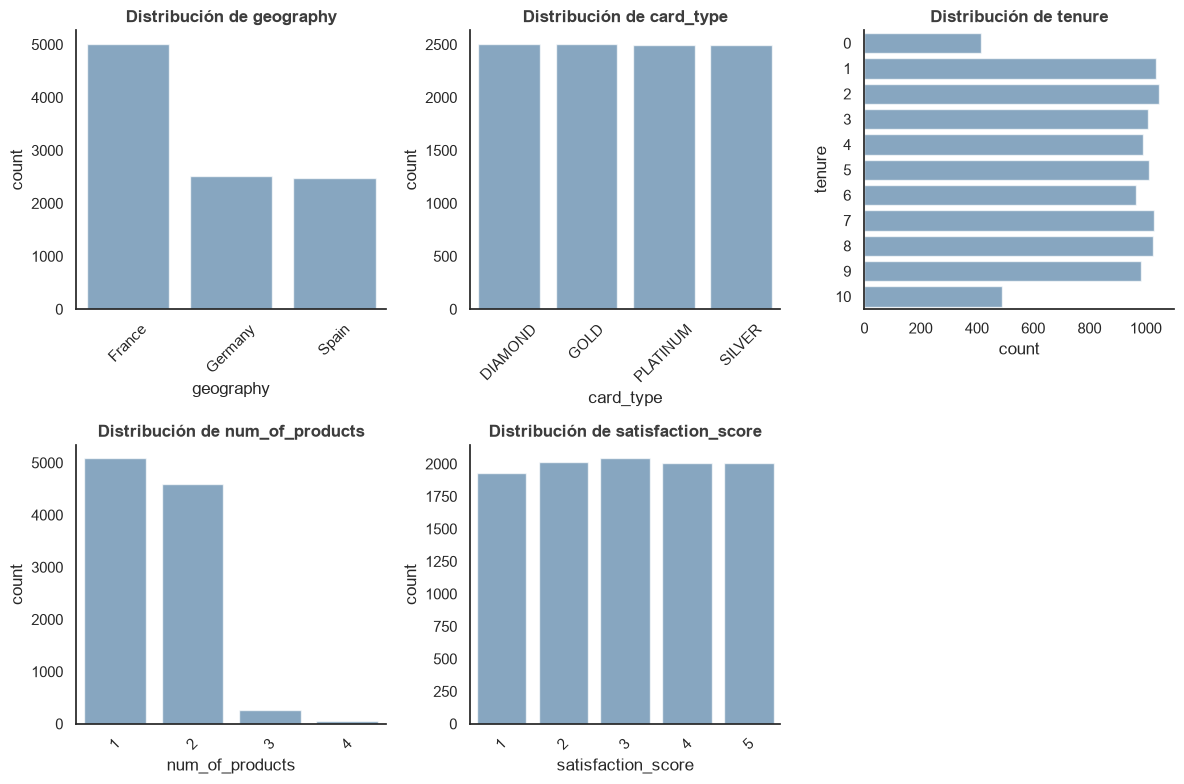

In [19]:
plot_categorical_counts_cla(df_cat, target, max_cat=10)

### Análisis Bivariado

#### Importancia de Variables

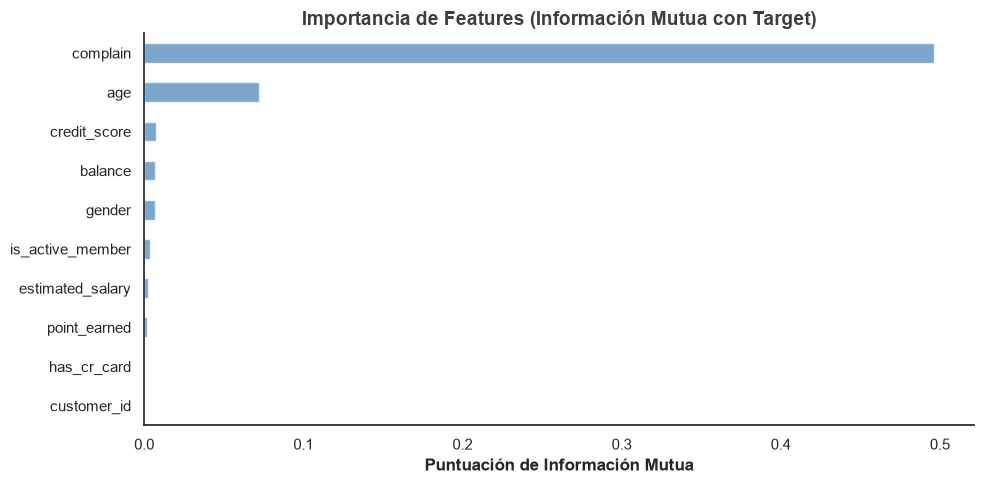

In [20]:
plot_feature_importance_min_cla(df, target)

#### Variables Numéricas vs Variable Objetivo

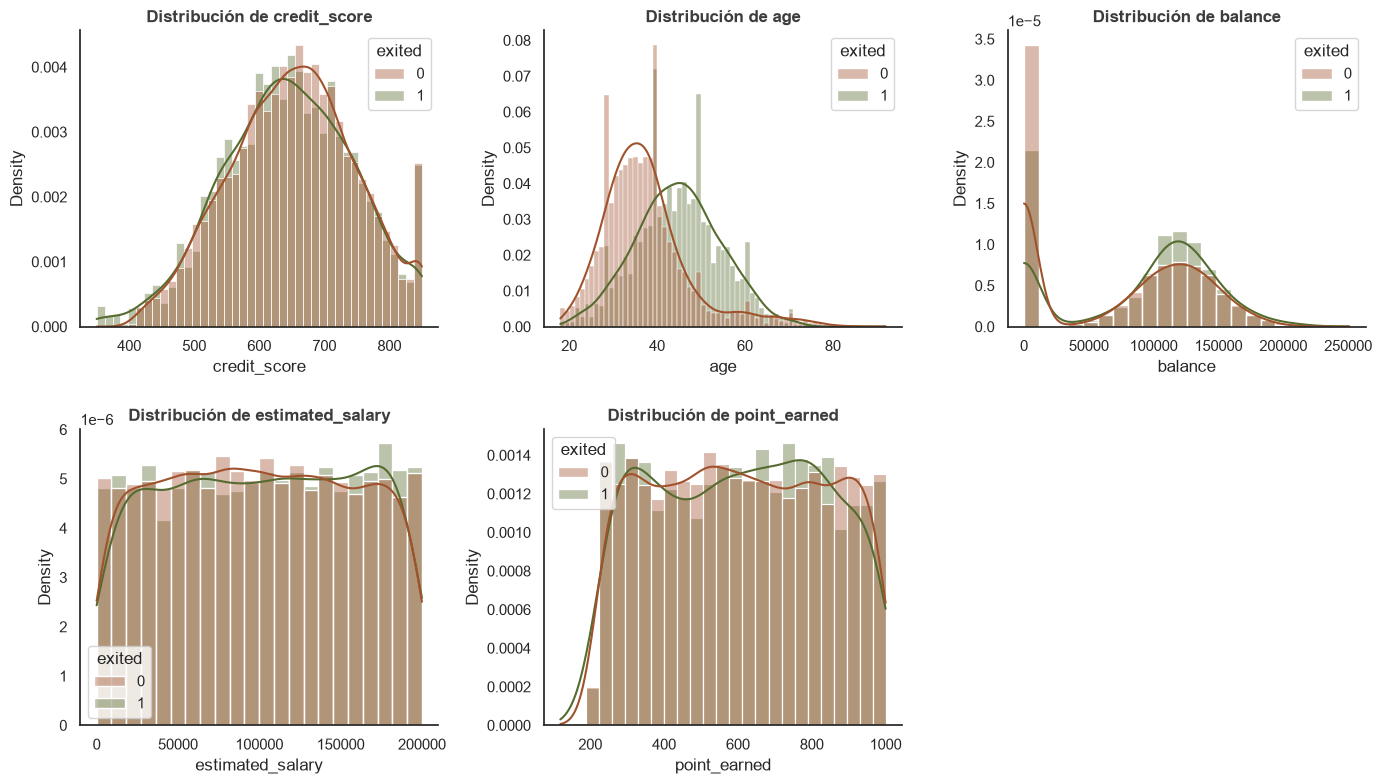

In [21]:
plot_all_numeric_distributions_cla_2(df_num, target)


Generando matriz mejorada de Diagramas de Violín...


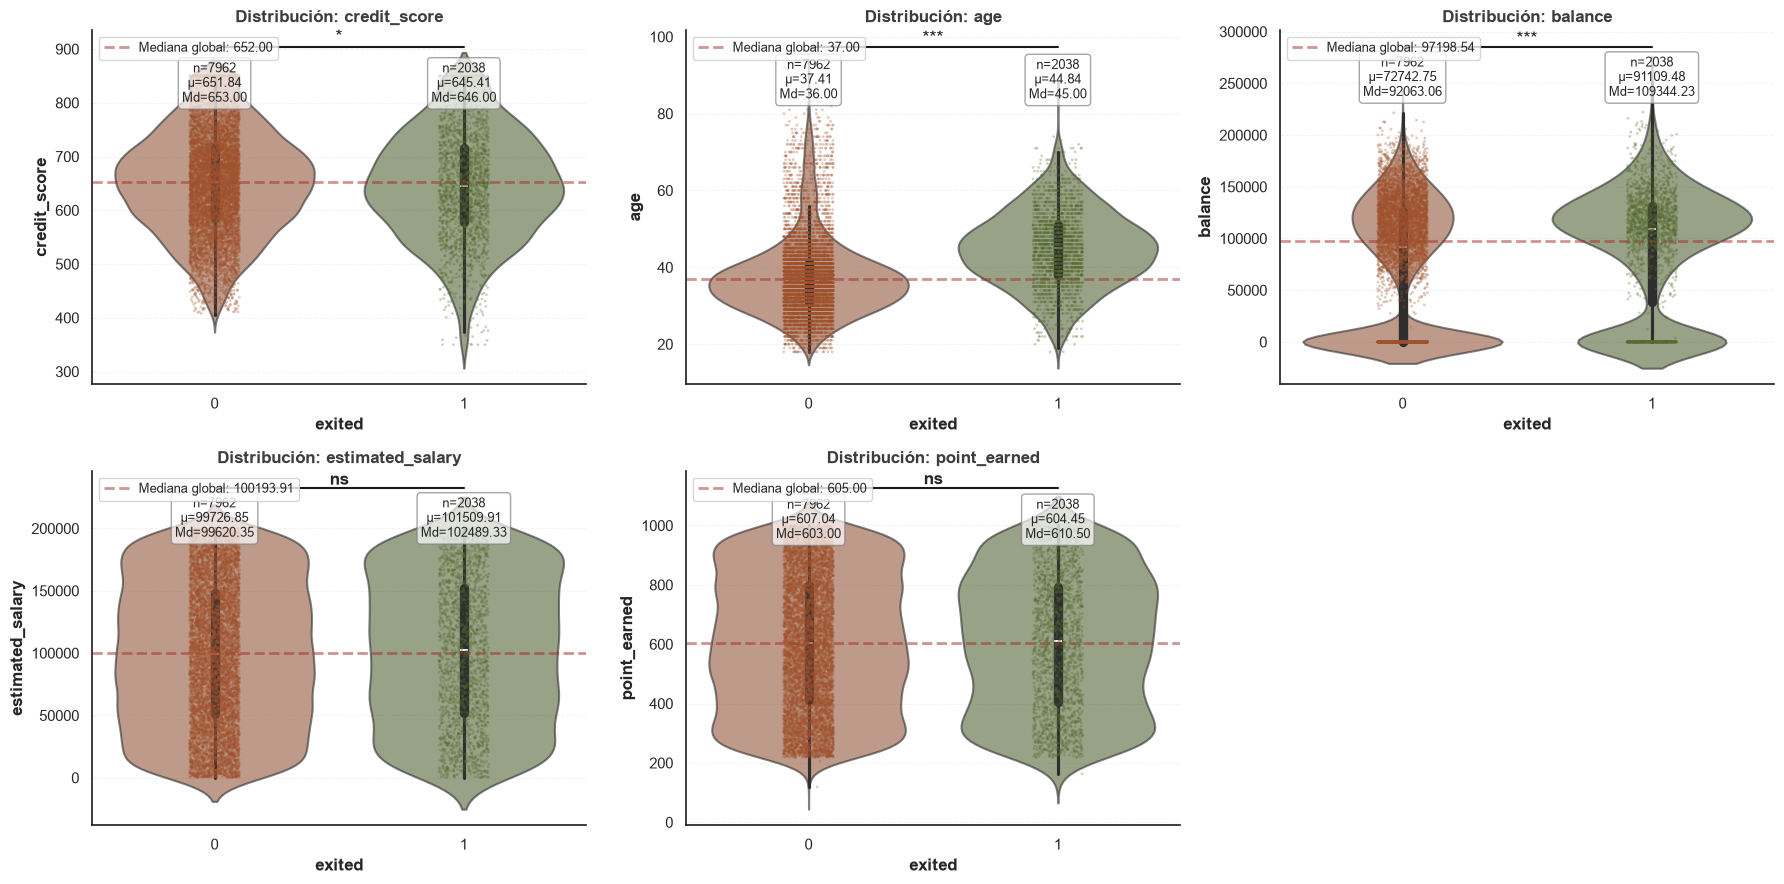

In [22]:
plot_violin_cla(df_num, target)

Analizando 10 combinaciones de variables...


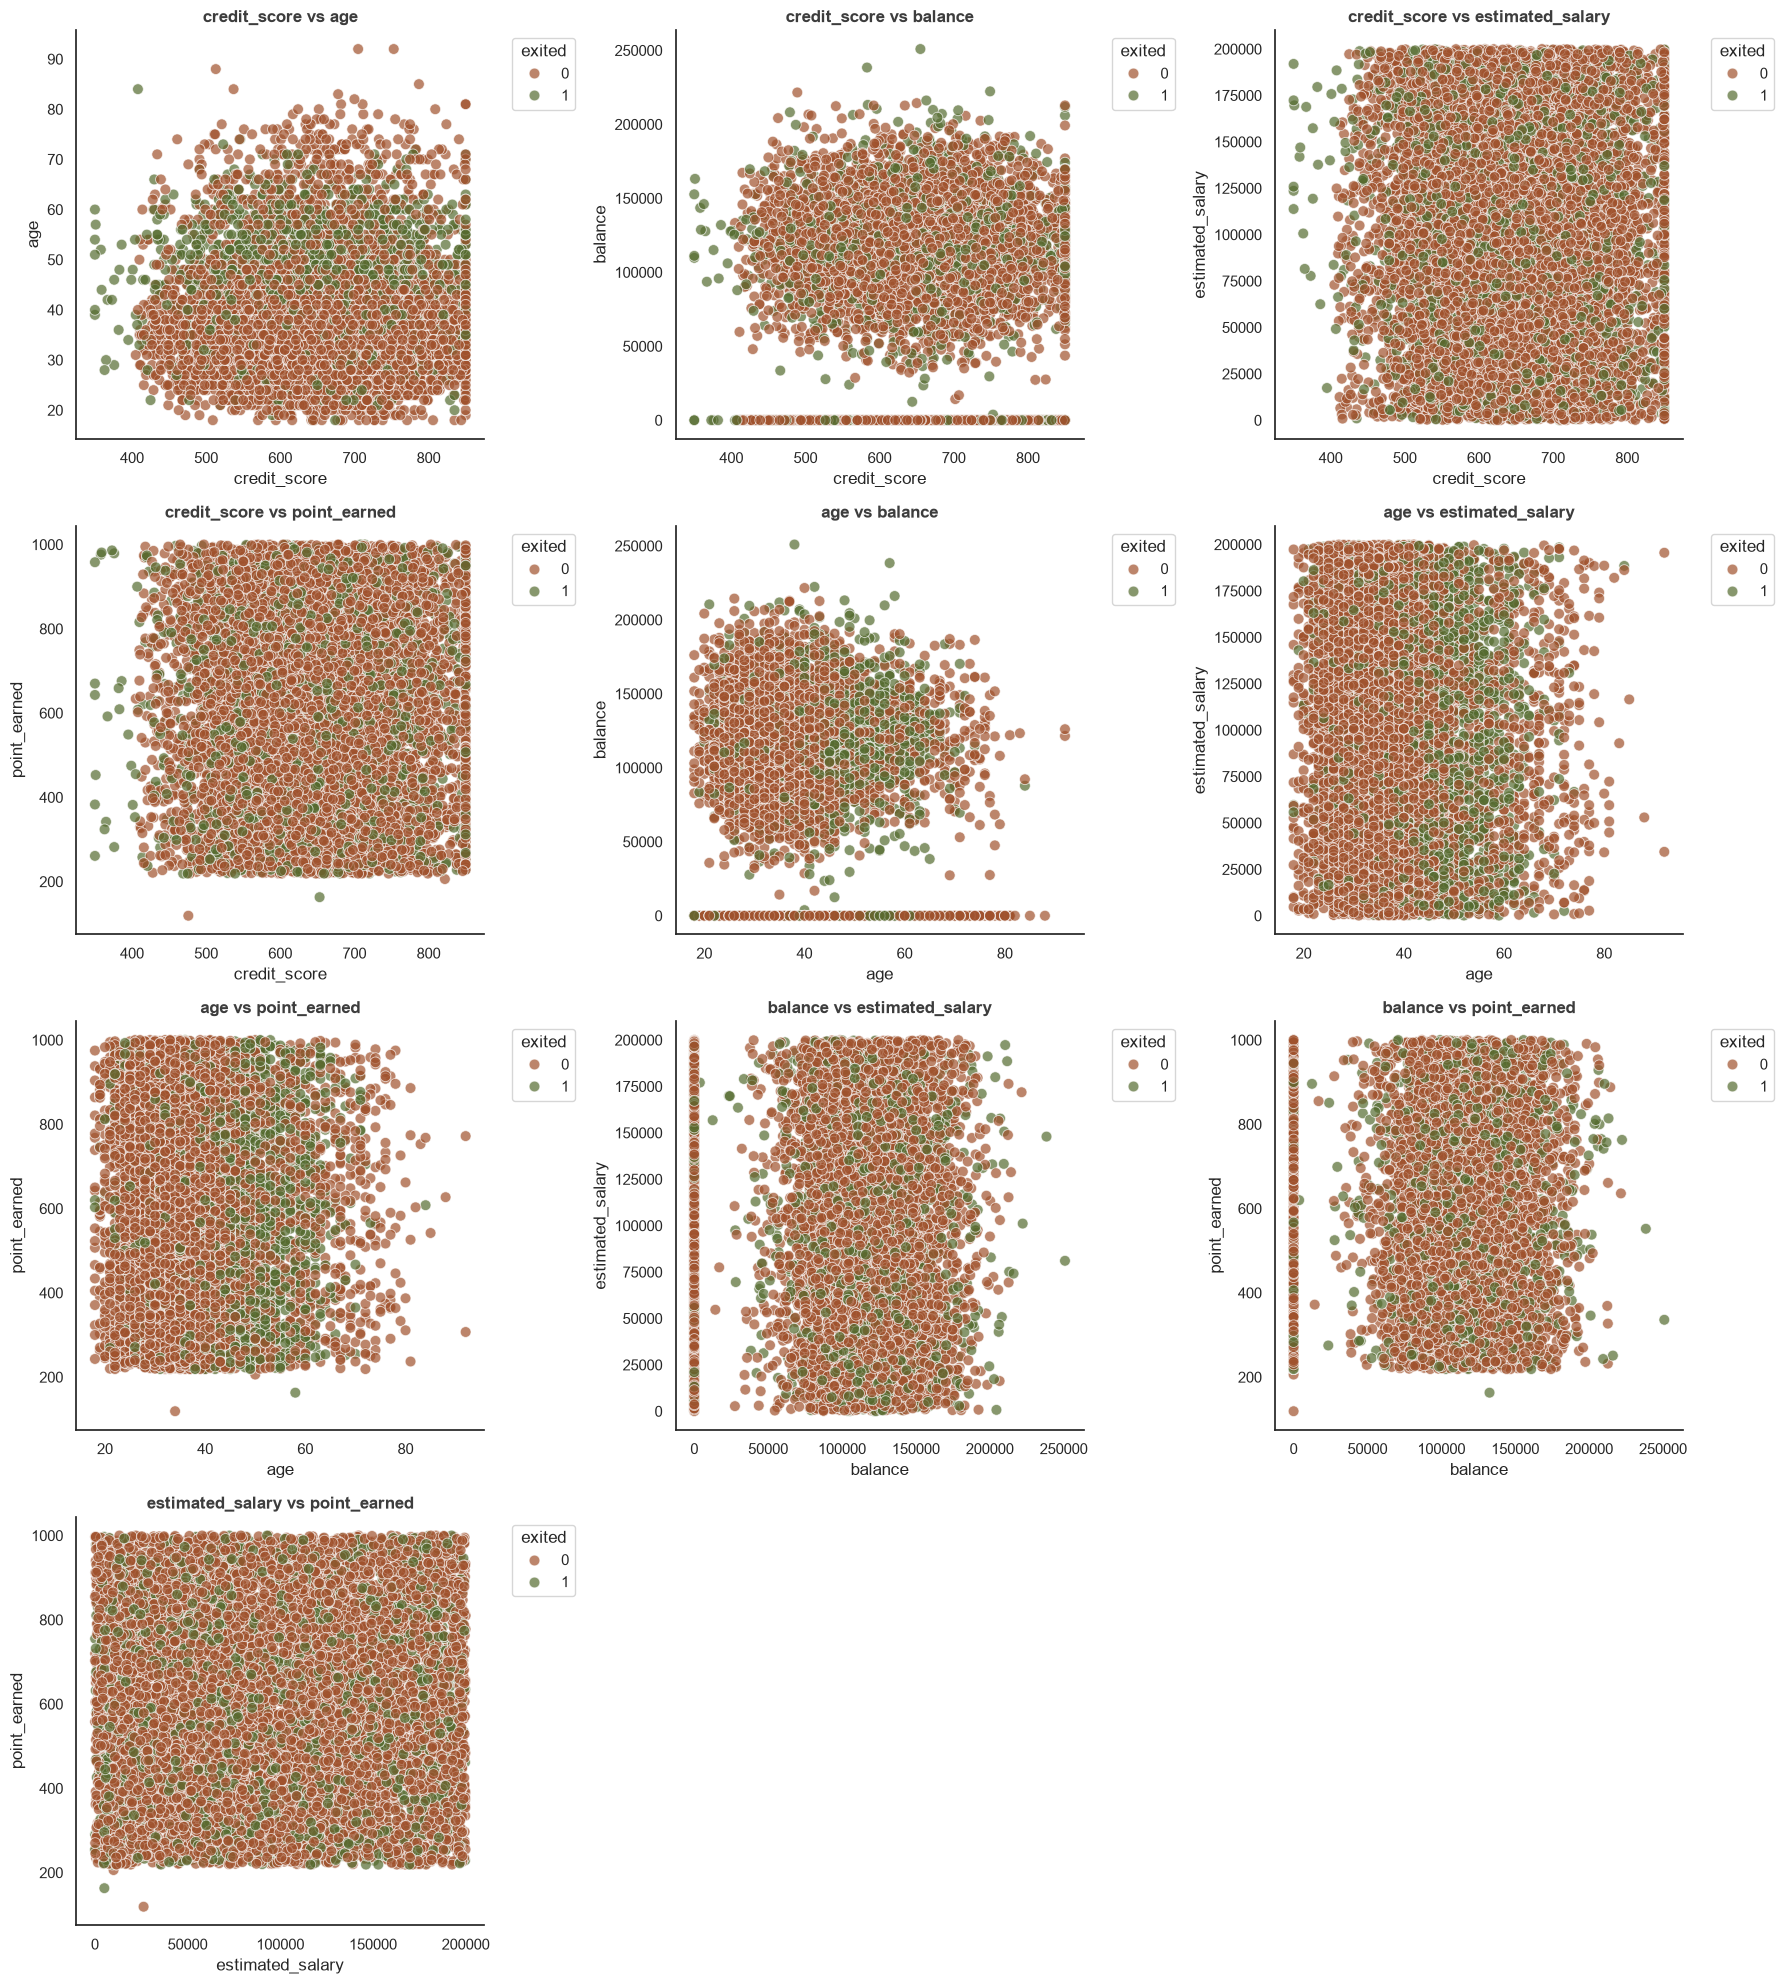

In [23]:
plot_relational_grid_cla(df_num, "exited")

#### Variables Binarias vs Variable Objetivo

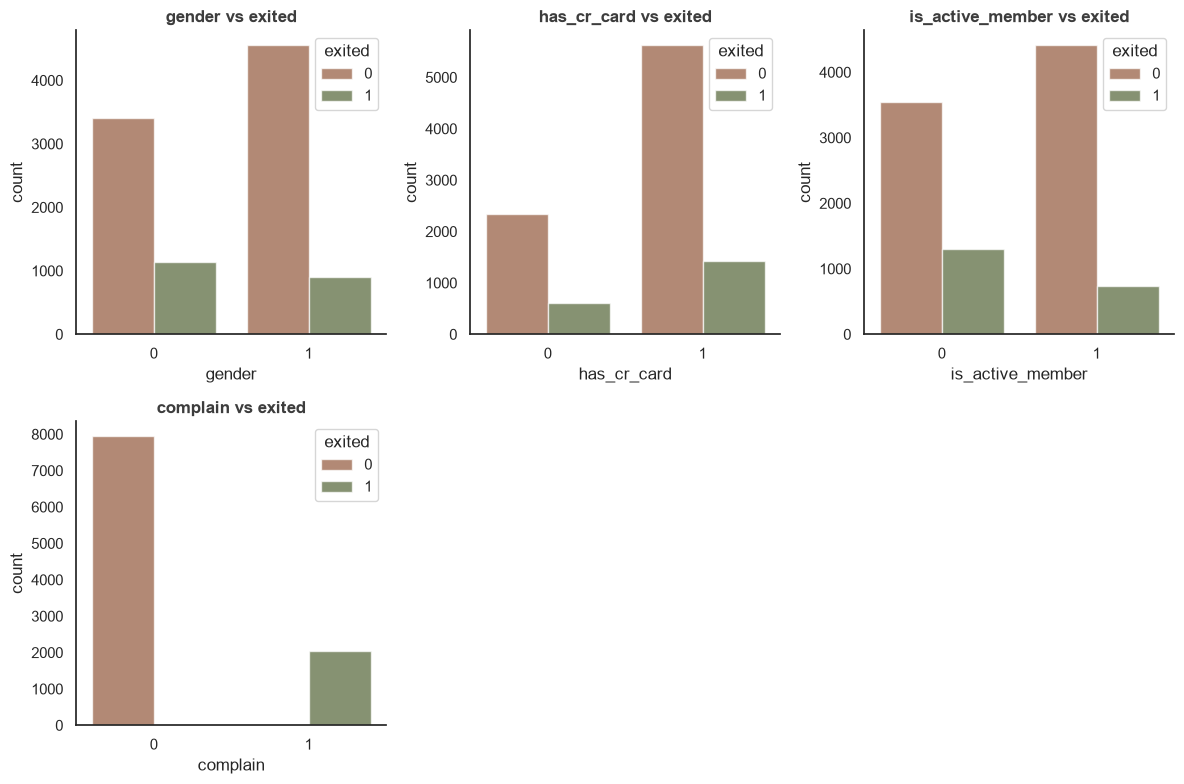

In [24]:
plot_bina_vs_target_cla(df_bina, target)

* **Sospechosa:** **`complain`**. *Por qué:* Presenta *data leakage* (fuga de datos). Las proporciones son perfectas: si es 0, nadie hace churn; si es 1, todos hacen churn. Es una variable trampa porque está determinando el resultado de forma directa. Se aconseja verificar con el responsable de dicha columna para confirmar como fue construida y si hay que hacerle algún cambio.


* **Muy útil:** **`is_active_member`**. *Por qué:* Muestra una diferencia clara en las tasas de abandono; los clientes inactivos (0) tienen mayor propensión a irse que los activos (1), aportando poder predictivo real.


* **Inútil:** **`has_cr_card`**. *Por qué:* La proporción de abandono es prácticamente idéntica entre tener o no tarjeta de crédito, ofreciendo muy poca discriminación para el modelo.

#### Variables Categóricas vs Variable Objetivo

In [25]:
get_categorical_features_report(df_cat, target)

,Feature,Max_Concentration,P_Value,Is_Significant,MI_Score,Verdict
3,num_of_products,50.84%,0.0000,YES,0.06939,KEEP
0,geography,50.14%,0.0000,YES,0.01847,KEEP
2,tenure,10.48%,0.1704,NO,0.00184,DISCARD
1,card_type,25.07%,0.1679,NO,0.00153,DISCARD
4,satisfaction_score,20.42%,0.4334,NO,0.00000,DISCARD


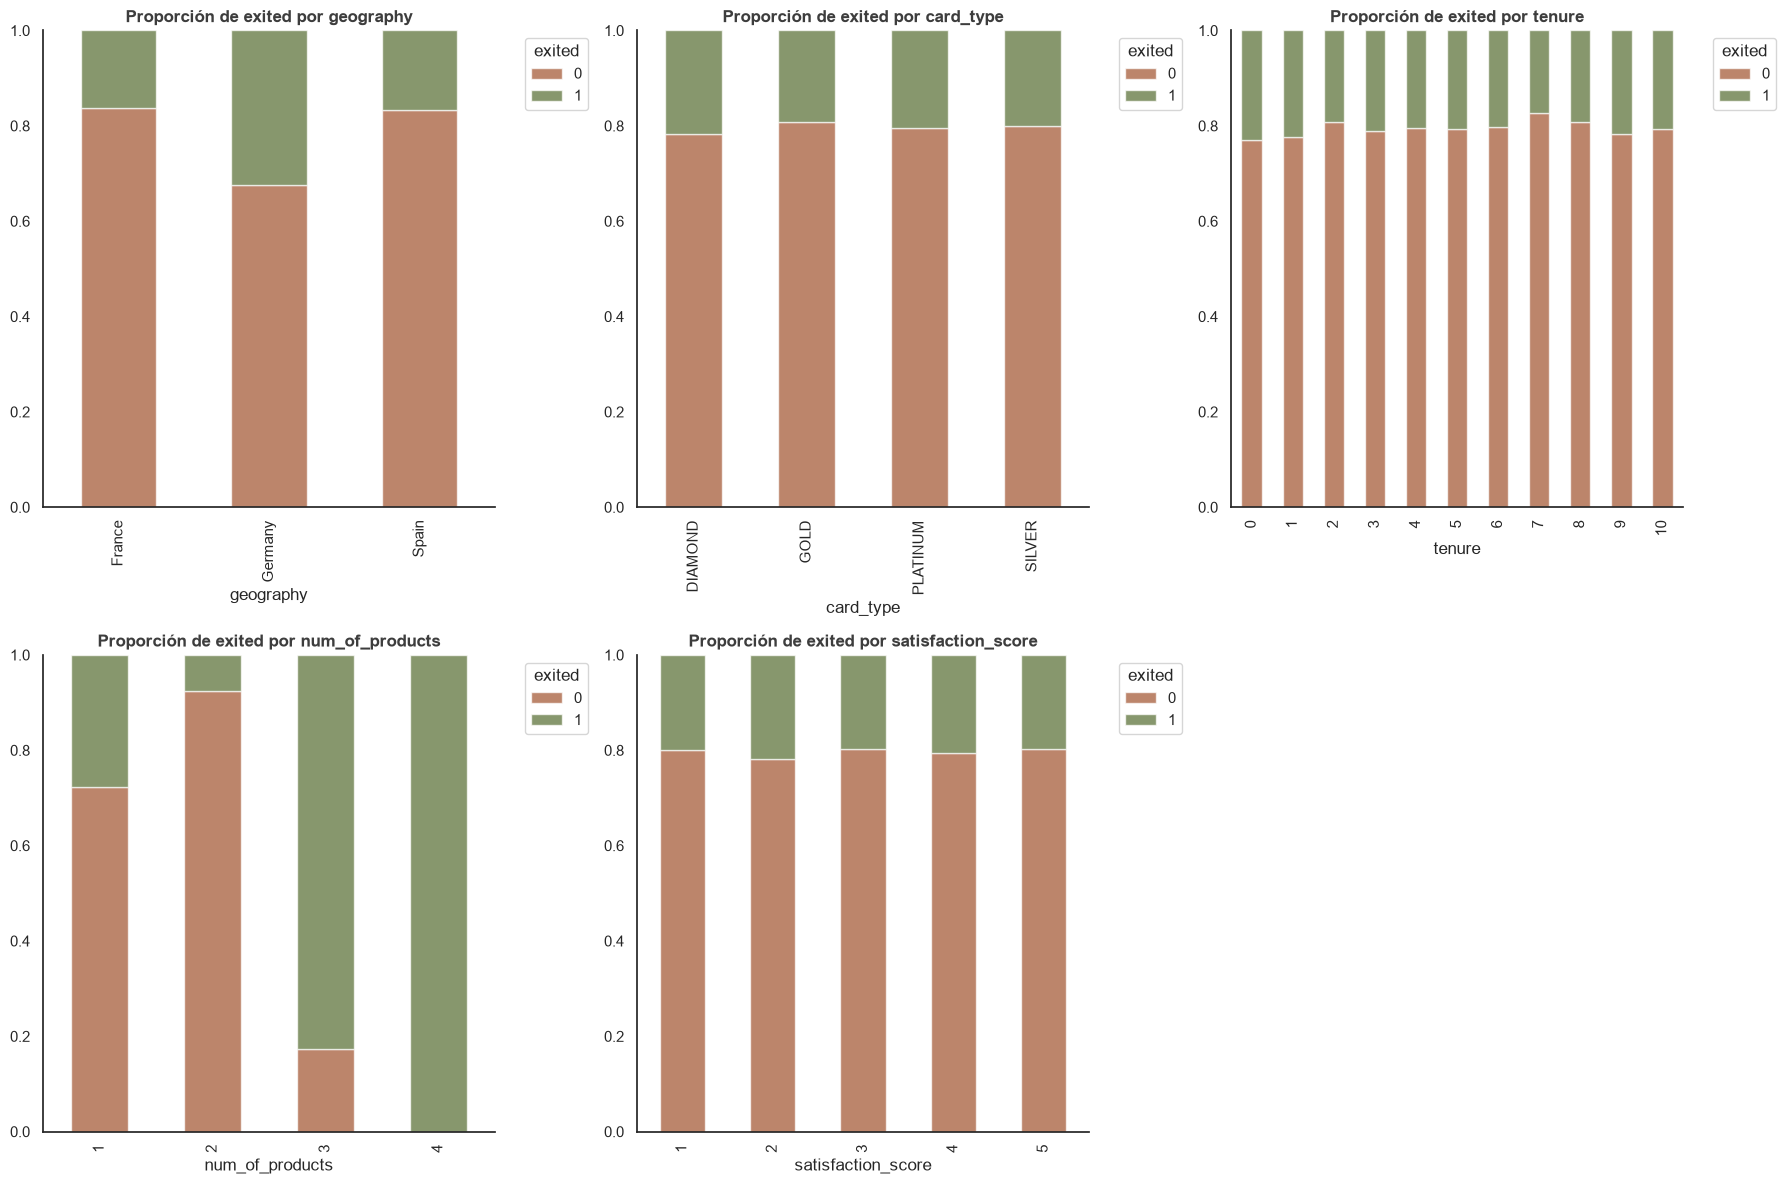

In [26]:
plot_categorical_vs_target_cla(df_cat, "exited")

- Muy útil: num_of_products.   Por qué: Muestra una variación drástica y crítica en el comportamiento; los clientes con 3 o 4 productos tienen una tasa de abandono masiva en comparación con los que tienen 2, aportando un poder predictivo altísimo al modelo.   

- Inútil: card_type (y también satisfaction_score o tenure).   Por qué: La proporción de abandono es prácticamente idéntica en todas sus categorías ( DIAMOND, GOLD, PLATINUM, SILVER ), ofreciendo nula capacidad de discriminación para predecir el churn.   

#### Variables Categóricas vs Variable Categóricas (opcional)

In [27]:
plot_crosstab_combinations_cla(df_cat, target='exited')


Tabla cruzada: geography vs card_type


card_type,DIAMOND,GOLD,PLATINUM,SILVER
geography,,,,
France,1230,1235,1264,1285
Germany,648,653,608,600
Spain,629,614,623,611



Tabla cruzada: geography vs tenure


tenure,0,1,2,3,4,5,6,7,8,9,10
geography,,,,,,,,,,,
France,205,529,525,491,512,485,503,552,465,504,243
Germany,105,264,275,261,232,259,227,225,264,269,128
Spain,103,242,248,257,245,268,237,251,296,211,119



Tabla cruzada: geography vs num_of_products


...

num_of_products,1,2,3,4
tenure,,,,
0,236,171,6,0
1,568,431,32,4
2,473,543,21,11
3,529,430,42,8
4,504,462,20,3
5,501,468,36,7
6,490,456,17,4
7,517,482,24,5
8,525,468,28,4



Tabla cruzada: tenure vs satisfaction_score


satisfaction_score,1,2,3,4,5
tenure,,,,,
0,87,85,75,76,90
1,195,204,218,206,212
2,228,205,211,195,209
3,186,211,197,211,204
4,205,203,199,177,205
5,208,199,198,210,197
6,156,191,208,224,188
7,207,220,198,195,208
8,188,220,204,228,185



Tabla cruzada: num_of_products vs satisfaction_score


satisfaction_score,1,2,3,4,5
num_of_products,,,,,
1,972,1006,1024,1046,1036
2,901,943,950,899,897
3,45,50,59,50,62
4,14,15,9,13,9


### Análisis Multivariado

#### Variables Numéricas

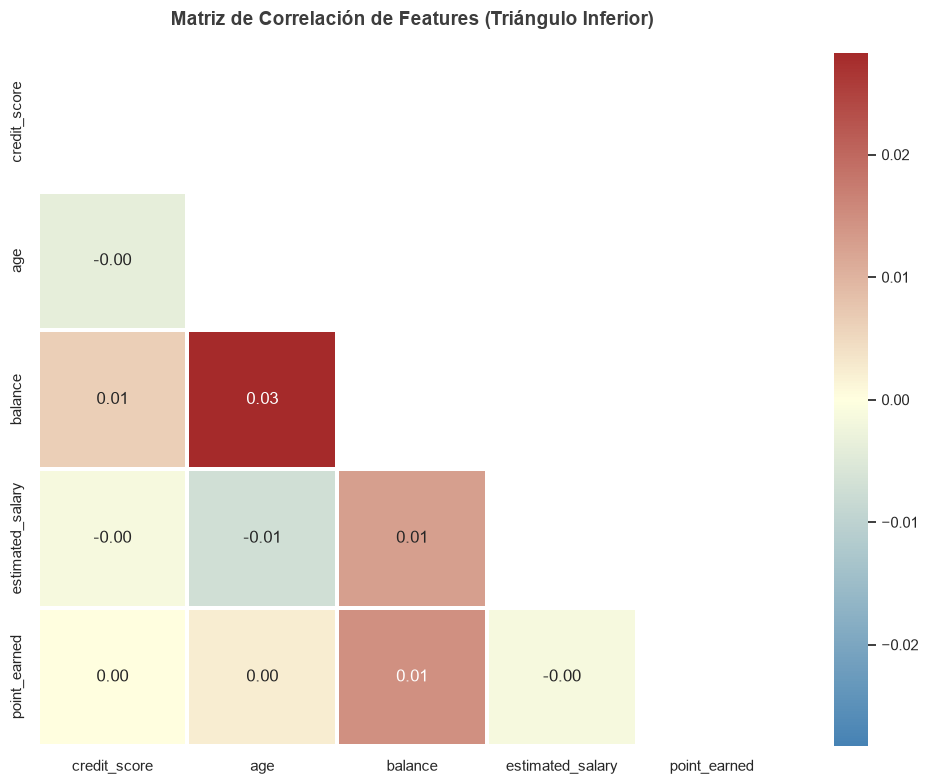


╔════════════════════════════════════════════════════════════════════════════╗
║                   INTERPRETACIÓN DE CORRELACIÓN DE FEATURES                ║
╠════════════════════════════════════════════════════════════════════════════╣
║ Correlación de Features → Alta: Multicolinealidad → Eliminar 1 o usar PCA  ║
║                                                                            ║
║ ADVERTENCIA: NO eliminar si:                                               ║
║  • Se usan modelos no lineales (Random Forest, XGBoost, Redes Neuronales)  ║
║  • Se usa regresión Ridge/Lasso (maneja multicolinealidad)                 ║
║  • El conocimiento del dominio del negocio sugiere su importancia          ║
╚════════════════════════════════════════════════════════════════════════════╝
    


In [39]:
plot_numeric_correlation_cla(df_num, target)

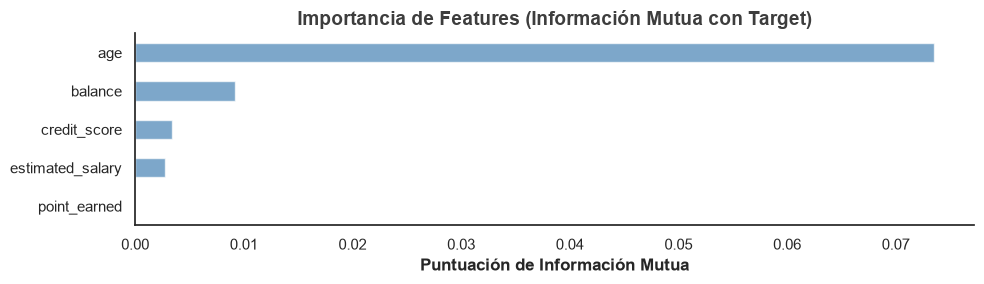

In [34]:
plot_feature_importance_min_cla(df_num, "exited")

#### Variables Categóricas


Graficando Matriz de Asociación Categórica Cramér's V...


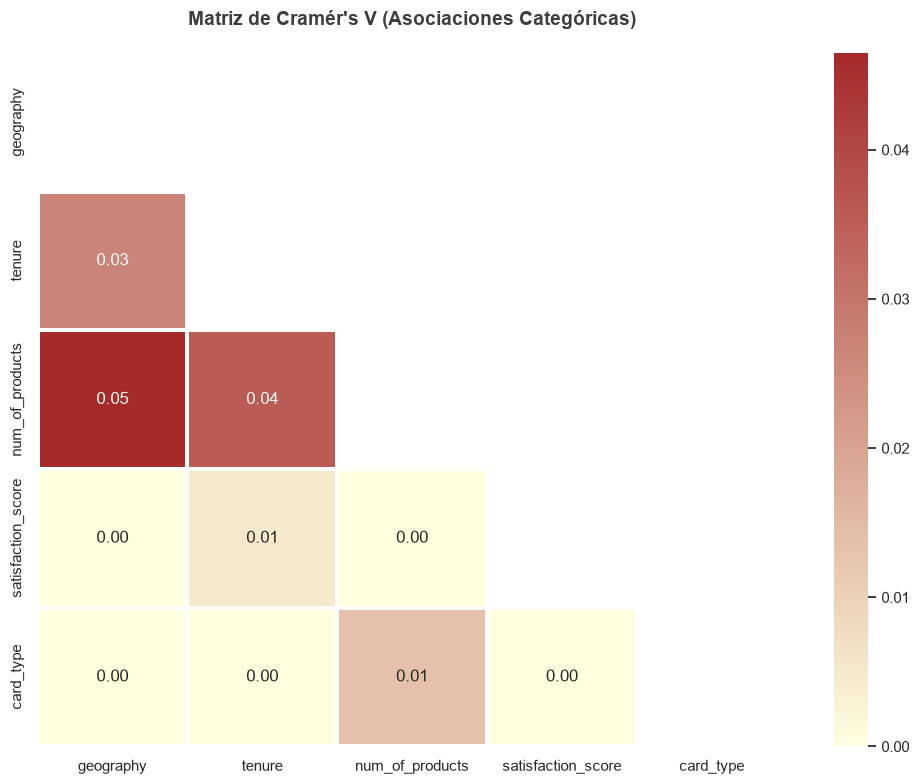

In [35]:
plot_categorical_correlation_cla(df)

## Alta Dimensionalidad

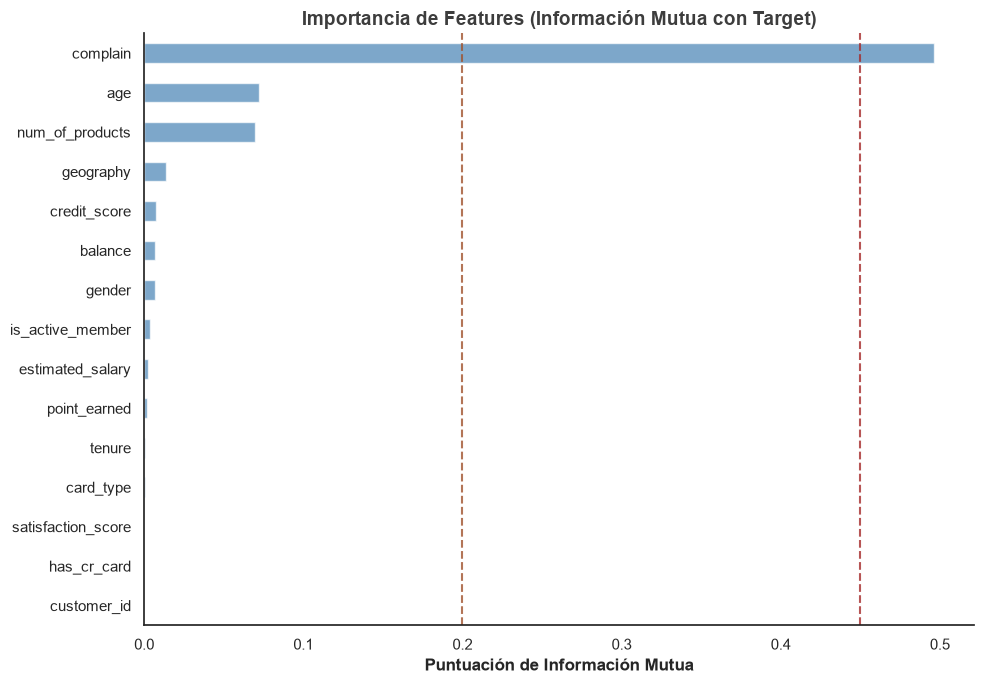

In [36]:
plot_feature_importance_max_cla(df, target)

## Influencia de Binarias

In [37]:
from scipy.stats import fisher_exact

# Tabla de contingencia (Cruce 100% real)
tabla_contingencia = pd.crosstab(df['complain'], df['exited'], margins=True)
print("=== TABLA DE CONTINGENCIA ===")
print(tabla_contingencia)

# Prueba Exacta de Fisher (Ideal para celdas con ceros o separación perfecta)
odds_ratio, p_value = fisher_exact(pd.crosstab(df['complain'], df['exited']))

print("\n=== MEDIDA DE INFLUENCIA ===")
print(f"Odds Ratio: {odds_ratio}")
print(f"p-value: {p_value:.4e} (Estadísticamente significativo)")

=== TABLA DE CONTINGENCIA ===
exited       0     1    All
complain                   
0         7952     4   7956
1           10  2034   2044
All       7962  2038  10000

=== MEDIDA DE INFLUENCIA ===
Odds Ratio: 404359.2
p-value: 0.0000e+00 (Estadísticamente significativo)


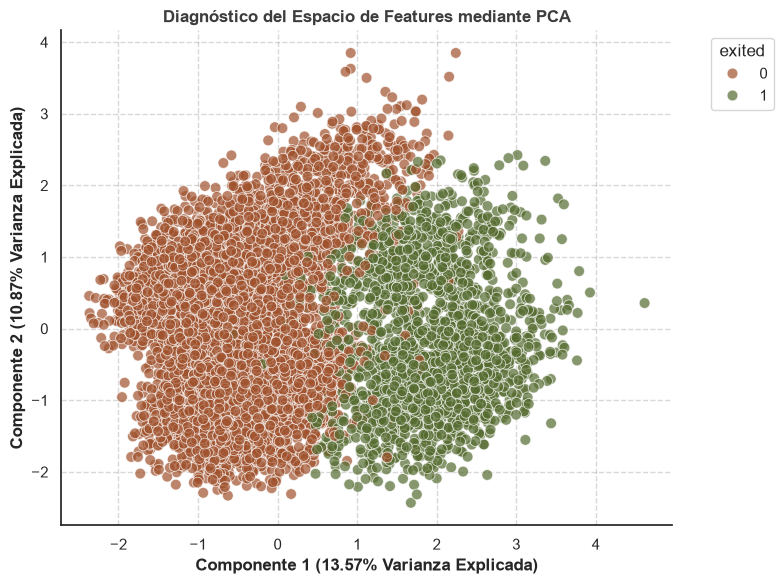

In [38]:
diagnostic_pca_dimensions_cla(df, target)

## Descarga

In [39]:
df.dropna(inplace=True)

In [40]:
df.to_csv("churn_EDA.csv", index=False)